In [1]:
import sys
import pandas as pd
sys.path.insert(0, "/Users/carang/Documents/pycharm document projects/SpotifyProj/docs")
from spotify_loading import load_history, align_end_dates, filter_window

data = "/Users/carang/Documents/pycharm document projects/SpotifyProj/data/"

#fetch the data for both people
cara = load_history(data + "my_spotify_data2 copy.zip", "Cara")
ruby = load_history(data + "my_spotify_datahenkek.zip", "Ruby")

#concatenate both peoples data
both_clean = align_end_dates(pd.concat([cara, ruby], ignore_index=True))

# pick a window
window = input("Select a time frame (all, 30d, 6m, 12m, year): ").strip().lower()

if window == "year":
    year = int(input("Which year? "))
    window_df = filter_window(both_clean, "year", year)
else:
    window_df = filter_window(both_clean, window)

print("now in window:" + window)


now in window:all


===== Clairo =====

Cara:
  First listened:  Jul 21, 2024
  First song:      4EVER
  Hours:           87.7
  Rank:            #10
  Top songs:
    - Bags (517 plays)
    - Amoeba (111 plays)
    - Juna (98 plays)
    - Slow Dance (96 plays)
    - 4EVER (90 plays)

Ruby:
  First listened:  Apr 19, 2021
  First song:      Bubble Gum
  Hours:           25.6
  Rank:            #41
  Top songs:
    - Bubble Gum (108 plays)
    - Pretty Girl (98 plays)
    - Bags (78 plays)
    - Sofia (39 plays)
    - Juna (34 plays)

🎧 Ruby listened first, by 1189 days
🏆 Bigger fan: Cara


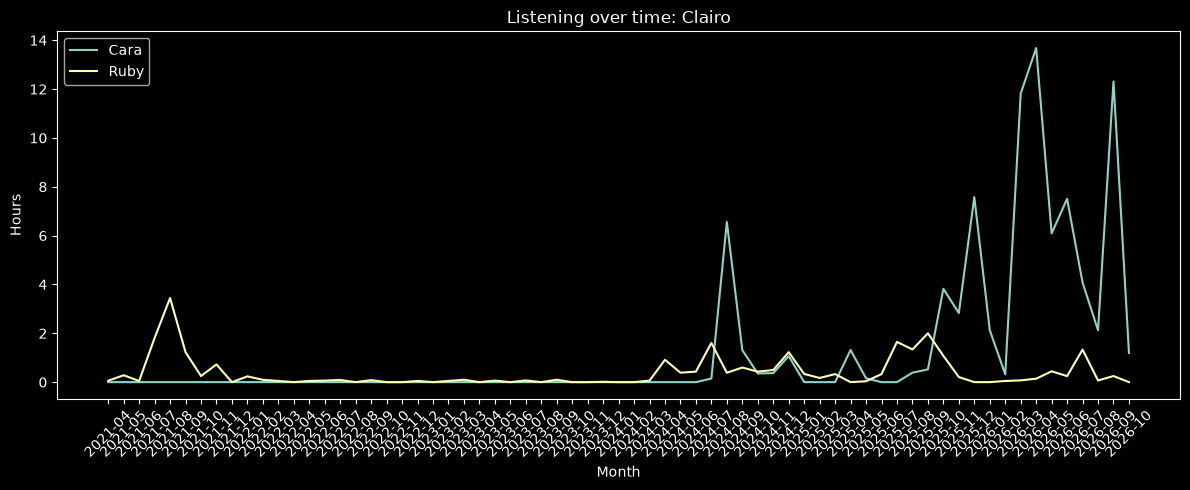

In [5]:
from artists_tab import artist_report
#run the block below before running this lmao

artist_input = input("Please enter the name of the artist: ")
result = artist_report(window_df, artist_input, "Cara", "Ruby")   # use a real artist
show_artist(result, "Cara", "Ruby")

In [4]:
#show the individual artist search in a better format
import matplotlib.pyplot as plt

def show_artist(result, person_a, person_b):
    if result is None:
        print("Artist not found.")
        return

    print(f"===== {result['artist']} =====\n")

    for person in [person_a, person_b]:
        stats = result[person]
        if stats is None:
            print(f"{person} has never listened to this artist.\n")
            continue

        print(f"{person}:")
        print(f"  First listened:  {stats['first_date'].strftime('%b %d, %Y')}")
        print(f"  First song:      {stats['first_song']}")
        print(f"  Hours:           {stats['hours']:.1f}")
        print(f"  Rank:            #{stats['rank']}")
        print(f"  Top songs:")
        for song, plays in stats["top_songs"].items():
            print(f"    - {song} ({plays} plays)")
        print()

    if "listened_first" in result:
        print(f"🎧 {result['listened_first']} listened first, by {result['gap_days']} days")
        print(f"🏆 Bigger fan: {result['bigger_fan']}")

    #plotting it
    timeline = pd.DataFrame(result["timeline"])
    plt.figure(figsize=(12, 5))
    plt.plot(timeline.index, timeline["Cara"], label="Cara")
    plt.plot(timeline.index, timeline["Ruby"], label="Ruby")
    plt.title(f"Listening over time: {result['artist']}")
    plt.xlabel("Month")
    plt.ylabel("Hours")
    plt.xticks(rotation=45)  # tilt month labels so they don't overlap
    plt.legend()  # shows which line is who
    plt.tight_layout()  # stops labels getting cut off
    plt.show()


In [6]:
#individual top artists
from artists_tab import show_individual_artists_ranking

table_A, table_B = show_individual_artists_ranking(window_df, "Cara", "Ruby")

print(table_A.head(20))
print(table_B.head(20))

               Cara_hours
artist                   
NewJeans       217.054509
SEVENTEEN      204.719742
TWICE          193.212891
aespa          188.918349
LE SSERAFIM    176.938541
BTS            117.702434
IVE             98.986093
Ariana Grande   98.268432
IZ*ONE          95.359156
Clairo          87.680173
Joe Hisaishi    83.245595
Red Velvet      81.726586
wave to earth   78.390526
Lamp            76.004354
BLACKPINK       71.890561
fromis_9        68.589199
Laufey          59.423324
ILLIT           58.167907
(G)I-DLE        57.759964
STAYC           56.420588
                    Ruby_hours
artist                        
TWICE               283.260157
GOT7                168.198915
The Kid LAROI       140.775199
iann dior           112.712699
Juice WRLD           91.504536
Lil Uzi Vert         86.482952
Stray Kids           79.985549
Drake                72.477099
IU                   71.470999
keshi                70.010482
BTS                  69.266944
Red Velvet           68.0

In [12]:
#shared top artists
from artists_tab import show_shared_artists_ranking

table = show_shared_artists_ranking(window_df, "Cara", "Ruby")
print(table.head(20))

                    Cara_hours  Ruby_hours  shared_score
artist                                                  
TWICE               193.212891  283.260157    193.212891
BTS                 117.702434   69.266944     69.266944
Red Velvet           81.726586   68.082259     68.082259
BLACKPINK            71.890561   64.921482     64.921482
Ariana Grande        98.268432   57.894133     57.894133
Tyler, The Creator   42.510088   38.872307     38.872307
NewJeans            217.054509   38.860412     38.860412
IU                   26.790195   71.470999     26.790195
DEAN                 36.056526   26.570656     26.570656
NCT DREAM            27.246378   26.261618     26.261618
Clairo               87.680173   25.567540     25.567540
beabadoobee          23.122163   26.389197     23.122163
SEVENTEEN           204.719742   21.625833     21.625833
Malcolm Todd         22.312348   20.939987     20.939987
Laufey               59.423324   20.461901     20.461901
ITZY                 33.004384 